# Import Modules

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# Parameters

In [2]:
start_date="11-11-2026"
#end_date="31-03-2027"
end_date="31-08-2027"
days_segment = 12

api = "http://10.7.32.34/cdm/Quotations/GetRData/fecd5650-13fd-403d-8ff6-601a5506c7cd?startDate="+start_date+"&endDate="+end_date+"&dates=true&simulation=0"

# Import Data

In [3]:
df=pd.read_csv(api)

In [4]:
df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date")
df.index.name=None

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 7055 entries, 2026-11-11 00:00:00 to 2027-08-31 23:00:00
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   value   7055 non-null   float64
dtypes: float64(1)
memory usage: 110.2 KB


In [6]:
df

,value
2026-11-11 00:00:00,267.071288
2026-11-11 01:00:00,261.018105
2026-11-11 02:00:00,258.198339
2026-11-11 03:00:00,256.861432
2026-11-11 04:00:00,259.085510
...,...
2027-08-31 19:00:00,203.969774
2027-08-31 20:00:00,223.452592
2027-08-31 21:00:00,226.213904
2027-08-31 22:00:00,222.519665


<Axes: >

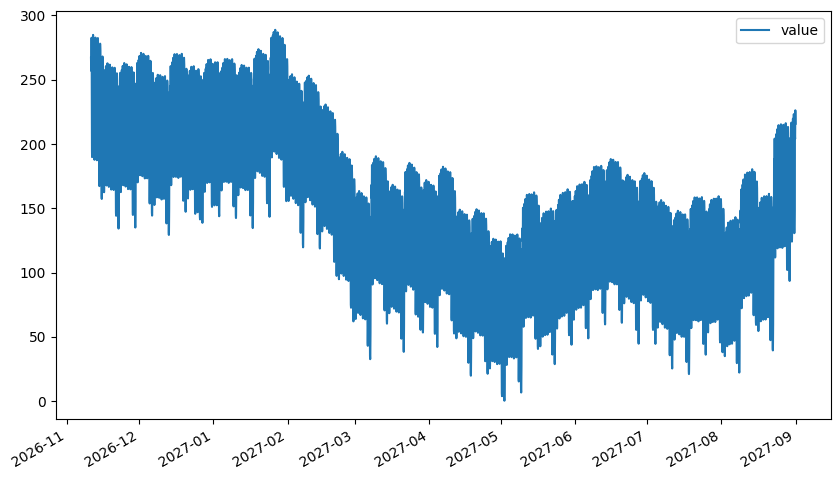

In [7]:
df.plot(figsize=(10,6))

# Simplistic Calculations (hour average)

In [8]:
monthly_average_series = df.groupby(df.index.month)["value"].mean()

In [9]:
monthly_average_series

1     225.822540
2     185.829553
3     130.244227
4     110.827463
5     104.827021
6     135.141589
7     112.771441
8     132.754380
11    223.229877
12    219.013955
Name: value, dtype: float64

## 1. Calculate average per hour across days

In [10]:
hourly_average_series = df.groupby(df.index.hour)["value"].mean()

## 2. Sort based on values (ascending)

In [11]:
hourly_average_sorted_series = hourly_average_series.sort_values()

In [12]:
hourly_average_sorted_series

11     95.879763
12     97.664218
10     99.884775
13    102.527631
9     110.841510
14    111.037477
15    126.281183
8     138.411217
16    152.823805
3     168.604941
2     169.978792
4     170.287608
7     171.911466
1     173.061625
17    174.172061
0     178.359561
5     179.289900
18    180.053061
19    180.500640
23    184.503569
6     186.770063
22    191.682745
20    193.976962
21    195.127481
Name: value, dtype: float64

### 2.1. Keep n cheapest hours

In [13]:
lowest_prices_series = hourly_average_series.nsmallest(days_segment).sort_values()

In [14]:
lowest_prices_series

11     95.879763
12     97.664218
10     99.884775
13    102.527631
9     110.841510
14    111.037477
15    126.281183
8     138.411217
16    152.823805
3     168.604941
2     169.978792
4     170.287608
Name: value, dtype: float64

In [15]:
print("Average of cheaper hours: {}".format(lowest_prices_series.mean()))

Average of cheaper hours: 128.68524330338207


### 2.2. Keep n most expensive hours

In [16]:
higher_prices_series = hourly_average_series.nlargest(days_segment).sort_values()

In [17]:
higher_prices_series

7     171.911466
1     173.061625
17    174.172061
0     178.359561
5     179.289900
18    180.053061
19    180.500640
23    184.503569
6     186.770063
22    191.682745
20    193.976962
21    195.127481
Name: value, dtype: float64

In [18]:
print("Average of expensive hours: {}".format(higher_prices_series.mean()))

Average of expensive hours: 182.45076124963737


# Realistic Calculation (n smallest / n largest per day)

In [19]:
lowest_n_series = (
    df.groupby(df.index.normalize(), group_keys=False)
      .apply(lambda day: day.nsmallest(days_segment, "value"))
      .sort_index())
highest_n_series = (
    df.groupby(df.index.normalize(), group_keys=False)
      .apply(lambda day: day.nlargest(days_segment, "value"))
      .sort_index())

In [20]:
#lowest_n_series.head(12).sort_values(by="value")

In [21]:
#highest_n_series.head(24)

In [22]:
avg_lowest_n_series = lowest_n_series.resample('D').mean()
avg_highest_n_series = highest_n_series.resample('D').mean()

In [23]:
min_of_means=avg_lowest_n_series.mean()
max_of_means=avg_highest_n_series.mean()

print("Mean of Min: {} \nMean of Max: {}".format(min_of_means.values[0], max_of_means.values[0]))

print("Mean of Min: {} \nMean of Max: {}".format(min_of_means.values[0], max_of_means.values[0]))
print("Std of Min: {} \nStd of Max: {}".format(avg_lowest_n_series.std().values[0], avg_highest_n_series.std().values[0]))

Mean of Min: 128.13647638685046 
Mean of Max: 182.99160929377695
Mean of Min: 128.13647638685046 
Mean of Max: 182.99160929377695
Std of Min: 50.820772104569095 
Std of Max: 49.713993744296396


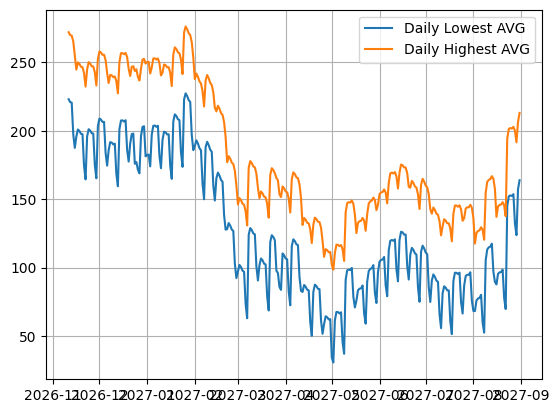

In [24]:
plt.figure()

plt.plot(avg_lowest_n_series.index, avg_lowest_n_series.value, label="Daily Lowest AVG")
plt.plot(avg_highest_n_series.index, avg_highest_n_series.value, label="Daily Highest AVG")

plt.legend()
plt.grid()

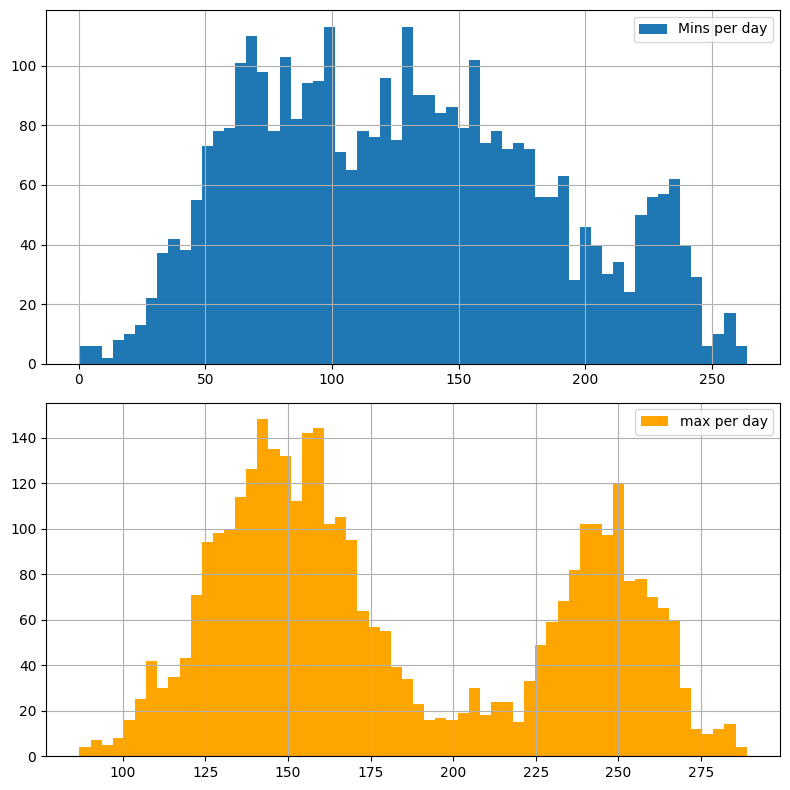

In [25]:
plt.figure(figsize=(8,8))
plt.subplot(2,1,1)
plt.hist(lowest_n_series, bins=60, label="Mins per day");
plt.grid()
plt.legend()

plt.subplot(2,1,2)
plt.hist(highest_n_series, bins=60, label="max per day", color="orange");
plt.tight_layout()
plt.grid()
plt.legend()

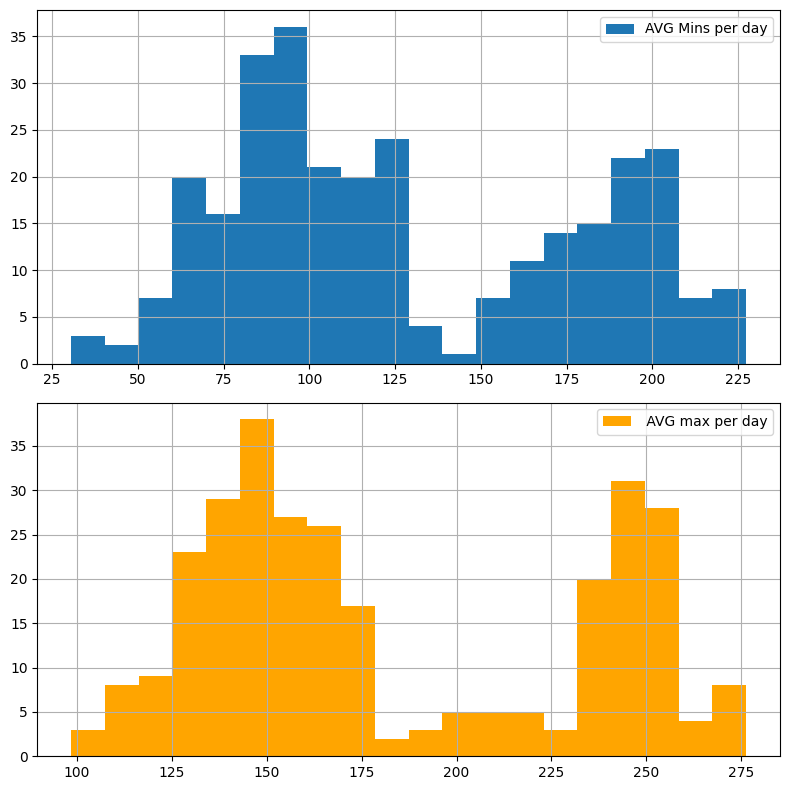

In [26]:
plt.figure(figsize=(8,8))
plt.subplot(2,1,1)
plt.hist(avg_lowest_n_series, bins=20, label="AVG Mins per day");
plt.grid()
plt.legend()

plt.subplot(2,1,2)
plt.hist(avg_highest_n_series, bins=20, label=" AVG max per day", color="orange");
plt.tight_layout()
plt.grid()
plt.legend()